# Identification

**Name:** David Rodríguez Fragoso  
**Student ID:** A01748760  
**Course:** TC6035 — Advanced Algorithms and Bioinspired Techniques  
**Problem:** Wireless sensor network placement  
**Instance salt:** 0  
**Route:** Provided mixed discrete–continuous problem

# Formulation


## Decision variables and objective

The deployment is represented by $\mathbf{x}=(\mathbf{z},\mathbf{p})$, with
$\mathbf{z}\in\{0,1\}^{80}$ and $p_i\in[1,c_i]$. The binary variable $z_i$
determines whether site $i$ is active, and $p_i$ sets its transmit power. Powers
assigned to inactive sites are ignored. Candidate coordinates, demand weights
and site-specific caps are fixed by the instance.

The field spans $[0,100]^2$. Demand is sampled at 2,500 points on a $50\times50$
grid covering the entire field. Candidate sites are a separate set of 80 positions.

The objective is maximized:

$$f(\mathbf{x})=C(\mathbf{x})-0.6E(\mathbf{x})-0.25I(\mathbf{x})-P(\mathbf{x}).$$

With $D=\sum_j d_j$, $k_j$ the number of active sensors covering point $j$, and
$n_a=\sum_i z_i$:

$$C=\frac{1}{D}\sum_{j:k_j>0}d_j,\qquad
E=\frac{25n_a+\sum_{i:z_i=1}p_i^2}{15600},\qquad
I=\frac{1}{D}\sum_{j:k_j>0}d_j\left(1-\frac{1}{k_j}\right).$$

Coverage rewards served demand; energy penalizes activation and quadratic power
cost; interference penalizes redundant coverage. All weights and normalization
constants are supplied by the problem and remain unchanged.

## Connectivity and infeasibility

An active sensor covers a disc of radius $r_i=4\sqrt{p_i}$. Active sites $i$ and
$\ell$ communicate if

$$\operatorname{dist}(i,\ell)\leq2.5\min(r_i,r_\ell).$$

A feasible deployment has exactly one connected component. Communication may
use intermediate sensors; direct links between every pair are unnecessary.
For a nonempty deployment with $m$ components:

$$P=\begin{cases}0,&m=1,\\2+0.1(m-1),&m>1.\end{cases}$$

The supplied evaluator separately assigns the empty deployment objective $-2$
and marks it infeasible.

The built-in penalty is used rather than repair. This keeps disconnected
candidates evaluable and provides a component-count penalty during search,
without introducing a repair operator that could change the search behavior.
Feasibility is recorded explicitly alongside the scalar objective.

Power changes coverage, energy, redundancy and communication links. Site
selection changes which power caps and links are available. These mechanisms
motivate an empirical coupling experiment in M0; they do not establish that a
particular hybrid must outperform joint search.

Source: course assignment specification, sections 2–3; `src/tc6035/problem.py` in the course repository.


# Implementations


In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for base in (Path.cwd(), *Path.cwd().parents):
    candidates = (base / "src", base / "tc6035-starter" / "src")
    src = next((p for p in candidates if (p / "tc6035").is_dir()), None)
    if src is not None:
        sys.path.insert(0, str(src))
        break
else:
    raise FileNotFoundError("Keep this notebook inside the course repository.")

from tc6035 import build_instance, SensorPlacementProblem, BudgetExceeded

STUDENT_ID = "A01748760"
SALT = 0
BUDGET = 5_000
SEEDS = tuple(range(30))

instance = build_instance(STUDENT_ID, salt=SALT)
spec = instance.spec

print(f"Python: {platform.python_version()} | NumPy: {np.__version__}")
print(f"Instance: {STUDENT_ID}, salt={SALT}")
print(f"Candidate sites: {instance.n_candidates}")
print(f"Demand points: {instance.n_grid}")
print(f"Power caps: {instance.power_cap.min():.2f}–{instance.power_cap.max():.2f}")
print(f"Final comparison seeds: {SEEDS}")

Python: 3.12.14 | NumPy: 2.3.5
Instance: A01748760, salt=0
Candidate sites: 80
Demand points: 2500
Power caps: 8.84–24.92
Final comparison seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)


In [2]:
def sample_deployment(rng, instance, fraction_range=(0.1, 0.5)):
    fraction = rng.uniform(*fraction_range)
    active = rng.random(instance.n_candidates) < fraction
    power = rng.uniform(instance.spec.power_min, instance.power_cap)
    return active, power


def random_walk(problem, seed, steps=1_000, power_step=3.0):
    rng = np.random.default_rng(seed)
    active, power = sample_deployment(rng, problem.instance)
    values = [problem.evaluate(active, power)]
    n = problem.instance.n_candidates

    for _ in range(steps):
        if rng.random() < 0.5 or not active.any():
            i = rng.integers(n)
            active[i] = ~active[i]
        else:
            i = rng.choice(np.flatnonzero(active))
            power[i] = np.clip(
                power[i] + rng.normal(0, power_step),
                problem.instance.spec.power_min,
                problem.instance.power_cap[i],
            )
        # Every move is accepted: this measures a neighborhood, not an optimizer.
        values.append(problem.evaluate(active, power))

    return np.asarray(values)


def monte_carlo(problem, seed, active_fraction_range=(0.1, 0.5), return_solution=False):
    low, high = active_fraction_range
    if not 0 < low < high < 1:
        raise ValueError("The activation-probability range must be inside (0, 1).")
    if problem.evaluations_remaining < 1:
        raise ValueError("Monte Carlo needs at least one remaining evaluation.")

    rng = np.random.default_rng(seed)
    best_score = -np.inf
    best_active = best_power = best_result = None

    while problem.evaluations_remaining > 0:
        active, power = sample_deployment(rng, problem.instance, active_fraction_range)
        result = problem.evaluate_verbose(active, power)
        if result.objective > best_score:
            best_score = result.objective
            best_active = active.copy()
            best_power = power.copy()
            best_result = result

    if return_solution:
        return float(best_score), best_active, best_power, best_result
    return float(best_score)


ALGORITHMS = {"monte_carlo": monte_carlo}

# M0

## Scope of this checkpoint

This checkpoint covers instance verification, visualization, feasibility, random-walk characterization and a 30-seed Monte Carlo baseline. The coupling experiment and simulated annealing remain to be implemented.

## Instance and evaluator checks

These checks use a separate evaluator and do not consume an optimization run budget. The single-sensor result is calculated independently from coordinates and the stated objective.

In [3]:
again = build_instance(STUDENT_ID, salt=SALT)
for name in ("candidates", "power_cap", "grid_points", "demand"):
    assert np.array_equal(getattr(instance, name), getattr(again, name))
assert instance.candidates.shape == (80, 2)
assert instance.grid_points.shape == (2_500, 2)
assert np.all(instance.demand > 0)
assert np.isclose(instance.demand.sum(), 1.0)

# Independent calculation for one active sensor using coordinates and formulas.
probe = SensorPlacementProblem(instance, budget=10, seed=900)
active = np.zeros(80, dtype=bool)
active[0] = True
power = np.full(80, spec.power_min)
power[0] = min(10.0, instance.power_cap[0])
distance = np.linalg.norm(instance.grid_points - instance.candidates[0], axis=1)
manual_coverage = instance.demand[distance <= 4 * np.sqrt(power[0])].sum()
manual_energy = (25 + power[0] ** 2) / 15_600
manual_f = manual_coverage - 0.6 * manual_energy
observed = probe.evaluate_verbose(active, power)
assert observed.feasible and observed.n_components == 1
assert np.isclose(observed.interference, 0)
assert np.isclose(observed.coverage, manual_coverage)
assert np.isclose(observed.energy, manual_energy)
assert np.isclose(observed.objective, manual_f)
print(f"Single-sensor check: manual={manual_f:.8f}, evaluator={observed.objective:.8f}")

# Two distant sensors at minimum power must be disconnected.
a, b = np.unravel_index(np.argmax(instance.dist_between), (80, 80))
assert instance.dist_between[a, b] > 10.0
active[:] = False
active[[a, b]] = True
power[:] = 1.0
observed = probe.evaluate_verbose(active, power)
manual_f = observed.coverage - 0.6 * observed.energy - 0.25 * observed.interference - 2.1
assert not observed.feasible and observed.n_components == 2
assert np.isclose(observed.objective, manual_f)

# Above-cap requests must have the same result as capped requests.
above = probe.evaluate(active, np.full(80, 100.0))
capped = probe.evaluate(active, instance.power_cap)
assert np.isclose(above, capped)

budget_probe = SensorPlacementProblem(instance, budget=2, seed=900)
budget_probe.evaluate_batch(np.stack([active, active]), np.stack([power, power]))
assert budget_probe.evaluations_used == 2
try:
    budget_probe.evaluate(active, power)
except BudgetExceeded:
    pass
else:
    raise AssertionError("The evaluator accepted an over-budget evaluation.")
assert len(budget_probe.record.values) == budget_probe.evaluations_used == 2
print("Determinism, connectivity penalty, caps and budget checks passed.")
print(f"Verification evaluations: {probe.evaluations_used + budget_probe.evaluations_used}")

Single-sensor check: manual=0.14584294, evaluator=0.14584294
Determinism, connectivity penalty, caps and budget checks passed.
Verification evaluations: 6


## Instance geometry and demand

The heatmap covers the full 100 by 100 field. Circles mark candidate locations, not demand points; circle size represents the site-specific power cap, not a coverage radius.

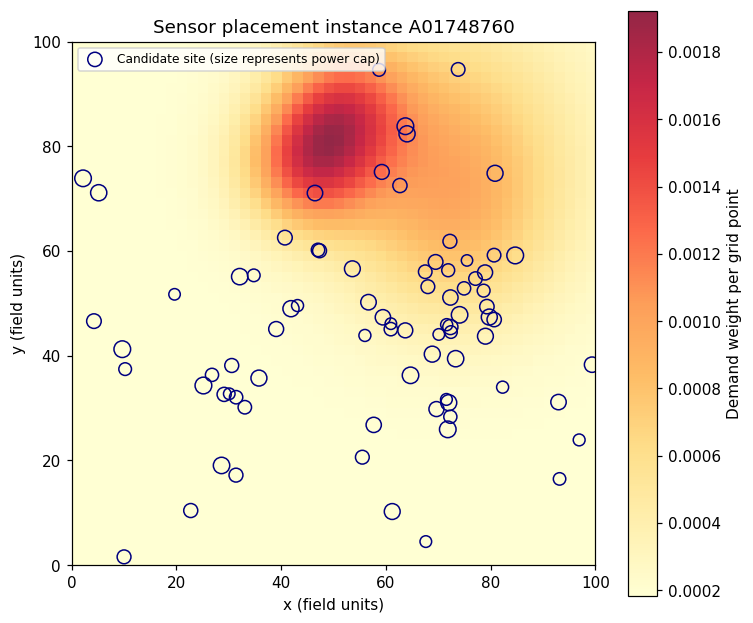

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
g = spec.grid_size
image = ax.imshow(
    instance.demand.reshape(g, g).T,
    origin="lower", extent=[0, 100, 0, 100], cmap="YlOrRd", alpha=0.85,
)
ax.scatter(
    instance.candidates[:, 0], instance.candidates[:, 1],
    s=20 + 100 * instance.power_cap / spec.power_max,
    facecolors="none", edgecolors="navy", linewidths=1,
    label="Candidate site (size represents power cap)",
)
fig.colorbar(image, ax=ax, label="Demand weight per grid point")
ax.set(xlabel="x (field units)", ylabel="y (field units)",
       title=f"Sensor placement instance {STUDENT_ID}", aspect="equal")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## Feasibility under random sampling

For each of 2,000 deployments, an activation probability is drawn uniformly from [0.1, 0.5], then each site is independently activated with that probability. Each power is drawn uniformly from [1, its own cap]. This characterizes the sampling distribution; it is separate from final optimizer runs.

In [5]:
CHAR_SEED = 10_000
N_DEPLOYMENTS = 2_000
rng = np.random.default_rng(CHAR_SEED)
characterization = SensorPlacementProblem(instance, budget=N_DEPLOYMENTS, seed=CHAR_SEED)
feasible_flags = []
component_counts = []
active_counts = []
sample_scores = []

for _ in range(N_DEPLOYMENTS):
    active, power = sample_deployment(rng, instance)
    result = characterization.evaluate_verbose(active, power)
    feasible_flags.append(result.feasible)
    component_counts.append(result.n_components)
    active_counts.append(result.n_active)
    sample_scores.append(result.objective)

feasible_flags = np.asarray(feasible_flags)
component_counts = np.asarray(component_counts)
active_counts = np.asarray(active_counts)
sample_scores = np.asarray(sample_scores)
feasible_fraction = float(feasible_flags.mean())
assert characterization.evaluations_used == N_DEPLOYMENTS

print(f"Feasible deployments: {feasible_flags.sum()}/{N_DEPLOYMENTS} ({feasible_fraction:.2%})")
print(f"Median active count: {np.median(active_counts):.1f}")
print(f"Median component count: {np.median(component_counts):.1f}")
print(f"Characterization evaluations: {characterization.evaluations_used}")

Feasible deployments: 330/2000 (16.50%)
Median active count: 24.0
Median component count: 3.0
Characterization evaluations: 2000


## Random-walk autocorrelation

The walk makes 1,000 moves and accepts every move. With probability 0.5 it flips one uniformly selected activation bit; otherwise it perturbs the power of a uniformly selected active sensor with Gaussian standard deviation 3, clipped to its bounds. An empty deployment forces a flip. The initial evaluation costs one additional call. This diagnostic depends on both the neighborhood and the sampled trajectory.

Lag-1 autocorrelation: 0.9353
Walk evaluations: 1001 (initial state + 1000 moves)


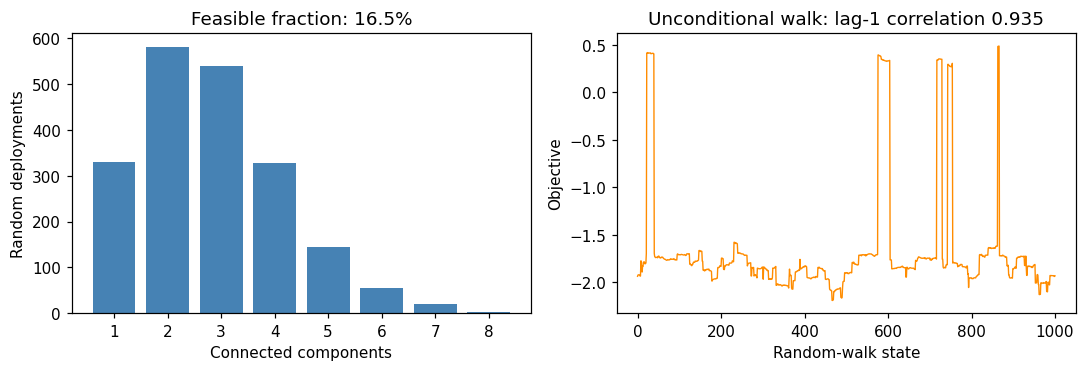

In [6]:
WALK_SEED = 10_001
WALK_STEPS = 1_000
WALK_POWER_STEP = 3.0
walk_problem = SensorPlacementProblem(instance, budget=WALK_STEPS + 1, seed=WALK_SEED)
walk_values = random_walk(walk_problem, WALK_SEED, WALK_STEPS, WALK_POWER_STEP)

assert walk_problem.evaluations_used == WALK_STEPS + 1
assert np.std(walk_values[:-1]) > 0 and np.std(walk_values[1:]) > 0
rho_1 = float(np.corrcoef(walk_values[:-1], walk_values[1:])[0, 1])

print(f"Lag-1 autocorrelation: {rho_1:.4f}")
print(f"Walk evaluations: {walk_problem.evaluations_used} (initial state + {WALK_STEPS} moves)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
components, frequencies = np.unique(component_counts, return_counts=True)
axes[0].bar(components, frequencies, color="steelblue")
axes[0].set(xlabel="Connected components", ylabel="Random deployments",
            title=f"Feasible fraction: {feasible_fraction:.1%}")
axes[0].set_xticks(components)
axes[1].plot(np.arange(walk_values.size), walk_values, lw=0.9, color="darkorange")
axes[1].set(xlabel="Random-walk state", ylabel="Objective",
            title=f"Unconditional walk: lag-1 correlation {rho_1:.3f}")
fig.tight_layout()
plt.show()

## Preliminary interpretation

The feasible fraction describes how often connected deployments appeared under the declared random-sampling procedure. It is not the fraction of all possible deployments that are feasible, and it may change with the activation and power distributions.

The measured lag-1 autocorrelation indicates a strong positive relationship between consecutive objective values in this walk: values above the trajectory mean tend to be followed by above-mean values, and below-mean values tend to be followed by below-mean values. The current value therefore carries information about the next one, but the correlation is not a prediction-accuracy percentage and does not mean that moves usually improve the objective.

This observation motivates testing whether neighborhood-based methods can exploit local structure. It does not establish that optimization will be easy or that any method will outperform Monte Carlo. The estimate depends on the move operator, step size and sampled trajectory; transitions between connected and disconnected deployments can also influence it through the penalty.

These are initial characterization results. Later sections will examine whether the proposed methods exploit this structure under the evaluation budget. Their convergence traces, internal-state diagnostics and paired comparisons will provide the evidence for the final analysis.


In [7]:
print(
    f"Under the declared random-deployment distribution, {feasible_fraction:.1%} "
    "of sampled deployments were connected. This is distribution-specific, "
    "not the fraction of all possible deployments that are feasible."
)
print(
    f"The lag-1 correlation was {rho_1:.3f} for the declared move operator and seed. "
    "It describes this walk; it does not establish global smoothness, "
    "unimodality or optimizer superiority."
)
print("The diagnostics above are characterization, not 30-seed optimizer results.")

Under the declared random-deployment distribution, 16.5% of sampled deployments were connected. This is distribution-specific, not the fraction of all possible deployments that are feasible.
The lag-1 correlation was 0.935 for the declared move operator and seed. It describes this walk; it does not establish global smoothness, unimodality or optimizer superiority.
The diagnostics above are characterization, not 30-seed optimizer results.


## Monte Carlo baseline

Each evaluation samples a fresh activation vector and power vector independently of previous samples, scores the complete deployment and retains the best solution found. A run uses exactly 5,000 evaluations, including every rejected or infeasible sample. The baseline uses the 30 declared seeds and no objective calls outside the instrumented evaluator.

An activation probability is sampled uniformly from [0.1, 0.5] for each deployment; sites are activated independently conditional on that probability. This covers expected deployment sizes from 8 to 40, spanning sparse and denser deployments without fixing one cardinality. It is the course's suggested starting range and matches the feasibility diagnostic. No range tuning has been performed. Extreme cardinalities remain possible but receive less sampling effort; the induced distribution is not uniform over all binary vectors. Powers are uniform within each site's own bounds.

The method returns the largest penalized objective, not the last evaluated score. Stored best vectors and objective components come from an already counted evaluation; reporting them spends no extra evaluations.

### Implementation checks

Small separate runs verify exact budget use, replay the same candidates independently, check the retained maximum and vectors, and verify seeded repeatability. These evaluations are reported separately from the baseline runs.

In [8]:
CHECK_SEED = 20_000
CHECK_BUDGET = 37
check_a = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
check_score, check_active, check_power, check_result = monte_carlo(
    check_a, CHECK_SEED, return_solution=True,
)

# Independent replay: sample the candidates and explicitly take their maximum.
check_b = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
replay_rng = np.random.default_rng(CHECK_SEED)
replay_scores = []
for _ in range(CHECK_BUDGET):
    active, power = sample_deployment(replay_rng, instance)
    replay_scores.append(check_b.evaluate(active, power))

assert np.isclose(check_score, max(replay_scores))
assert np.array_equal(check_a.record.values, check_b.record.values)
assert np.array_equal(check_a.record.best_so_far, np.maximum.accumulate(replay_scores))
assert check_a.evaluations_used == check_b.evaluations_used == CHECK_BUDGET
assert check_active.dtype == bool and check_active.shape == (80,)
assert np.all((check_power >= spec.power_min) & (check_power <= instance.power_cap))

# The returned vectors must reproduce the saved best result in a separate check.
solution_probe = SensorPlacementProblem(instance, budget=1, seed=CHECK_SEED)
assert np.isclose(solution_probe.evaluate(check_active, check_power), check_score)

repeat_probe = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
assert monte_carlo(repeat_probe, CHECK_SEED) == check_score
assert np.array_equal(repeat_probe.record.values, check_a.record.values)
MC_CHECK_EVALUATIONS = 3 * CHECK_BUDGET + 1
print("Monte Carlo checks passed: exact budget, independent replay, best solution and seeded repeatability.")
print(f"Separate verification evaluations: {MC_CHECK_EVALUATIONS}")

Monte Carlo checks passed: exact budget, independent replay, best solution and seeded repeatability.
Separate verification evaluations: 112


### Thirty-seed experiment

Each seed starts a fresh evaluator on the same instance. Run traces are saved locally for later comparisons and are not separate submission files. The returned score is checked against both the recorded best and the maximum evaluated value.

In [9]:
from time import perf_counter
from tc6035.runlog import RunSet, save_runset

MC_PARAMS = {"active_fraction_range": (0.1, 0.5)}
mc_records, mc_solutions = [], []
mc_run_seconds = []

for i, seed in enumerate(SEEDS):
    prob = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    started = perf_counter()
    score, active, power, result = monte_carlo(
        prob, seed, **MC_PARAMS, return_solution=True,
    )
    mc_run_seconds.append(perf_counter() - started)
    assert prob.evaluations_used == len(prob.record.values) == BUDGET
    assert score == prob.record.best == max(prob.record.values)
    mc_records.append(prob.record)
    mc_solutions.append((active, power, result))
    if (i + 1) % 5 == 0:
        print(f"Monte Carlo: {i + 1}/{len(SEEDS)} seeds complete", flush=True)

mc_scores = np.array([record.best for record in mc_records])
MC_BASELINE_MEDIAN = float(np.median(mc_scores))
MC_Q1, MC_Q3 = np.percentile(mc_scores, [25, 75])
MC_IQR = float(MC_Q3 - MC_Q1)
mc_used = np.array([record.evaluations_used for record in mc_records])
mc_feasible_bests = sum(result.feasible for _, _, result in mc_solutions)

save_runset(
    "results/m0_monte_carlo.npz",
    RunSet(algorithm="monte_carlo", student_id=STUDENT_ID,
           params={**MC_PARAMS, "salt": SALT}, records=mc_records),
)

print(f"Seeds: {SEEDS}")
print(f"Median final objective: {MC_BASELINE_MEDIAN:.6f}")
print(f"Q1–Q3: [{MC_Q1:.6f}, {MC_Q3:.6f}] | IQR width: {MC_IQR:.6f}")
print(f"Connected best solutions: {mc_feasible_bests}/{len(SEEDS)}")
print(f"Evaluations per run: min={mc_used.min()}, max={mc_used.max()}")
print(f"Total baseline evaluations: {mc_used.sum():,}")
print(f"Median runtime per run: {np.median(mc_run_seconds):.2f} seconds")

Monte Carlo: 5/30 seeds complete
Monte Carlo: 10/30 seeds complete
Monte Carlo: 15/30 seeds complete
Monte Carlo: 20/30 seeds complete
Monte Carlo: 25/30 seeds complete
Monte Carlo: 30/30 seeds complete
Seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)
Median final objective: 0.551577
Q1–Q3: [0.540722, 0.561175] | IQR width: 0.020453
Connected best solutions: 30/30
Evaluations per run: min=5000, max=5000
Total baseline evaluations: 150,000
Median runtime per run: 1.32 seconds


### Baseline convergence and variation

The full view retains the initial negative scores, which arise from disconnected sampled deployments. A second view enlarges evaluations 100–5,000 with vertical limits derived from the same median and quartile data; it introduces no additional run or resampling. The band shows Q1–Q3 of the 30 best-so-far traces at each evaluation. The curve is a pointwise median across runs, not the trajectory of one seed.

The final-score scatter shows one retained best value per seed after 5,000 evaluations. Its vertical scale differs because it contains only final scores. The expanded view and printed checkpoints expose later improvements hidden by the full vertical range. These figures do not by themselves establish convergence to an optimum or replace later mechanism-specific diagnostics.


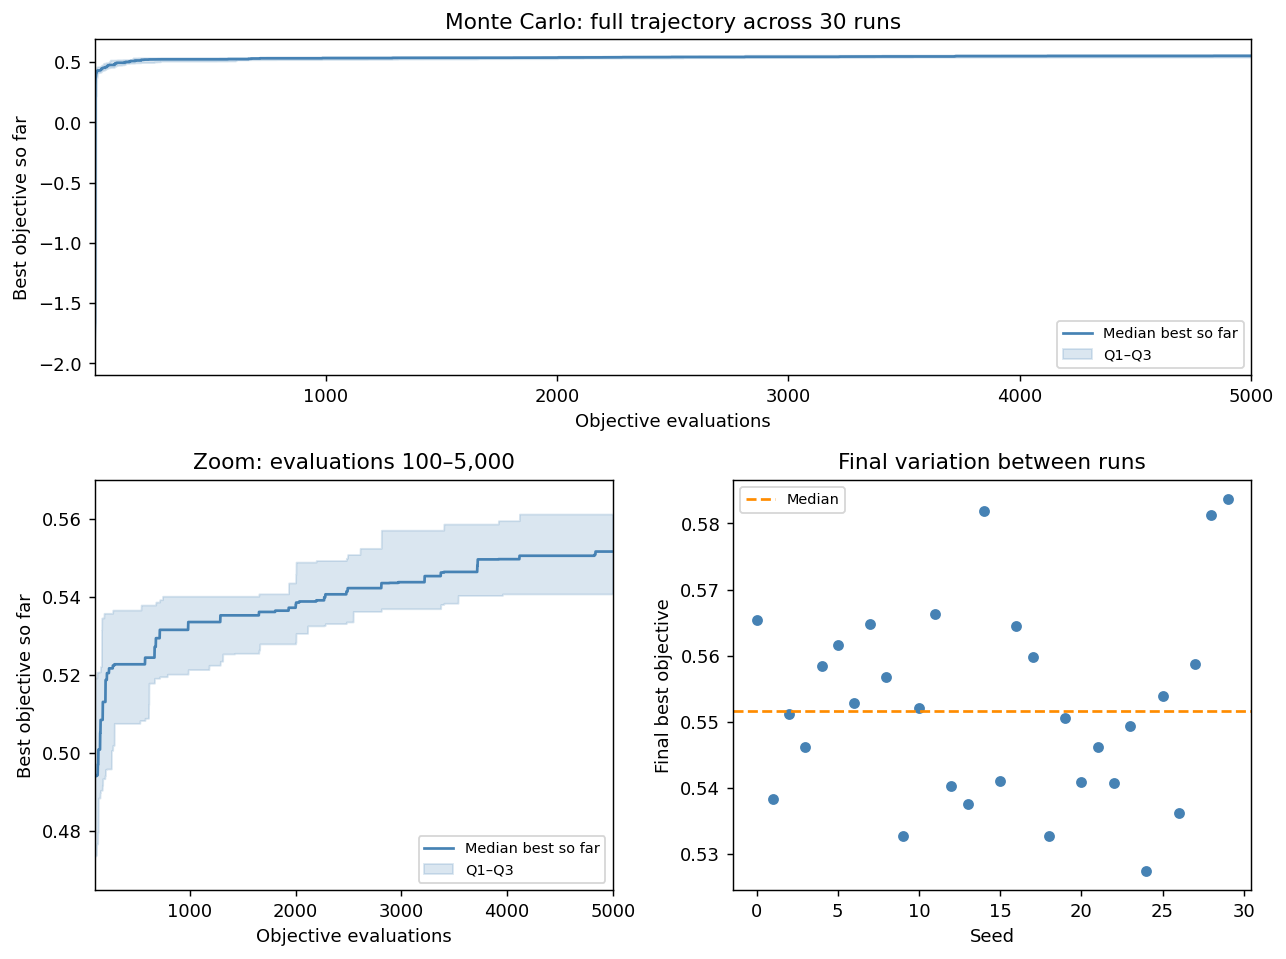

Median best at evaluation 100: 0.494076
Median best at evaluation 1,000: 0.533529
Median best at evaluation 5,000: 0.551577
Runs improving after evaluation 1,000: 27/30


In [10]:
mc_traces = np.array([record.best_so_far for record in mc_records])
trace_q1, trace_median, trace_q3 = np.percentile(mc_traces, [25, 50, 75], axis=0)
evaluations = np.arange(1, BUDGET + 1)
MC_ZOOM_START = 100
zoom = evaluations >= MC_ZOOM_START

fig = plt.figure(figsize=(10, 7.5))
grid = fig.add_gridspec(2, 2, height_ratios=[0.9, 1.1])
full_ax = fig.add_subplot(grid[0, :])
zoom_ax = fig.add_subplot(grid[1, 0])
scores_ax = fig.add_subplot(grid[1, 1])

for ax, mask in ((full_ax, np.ones(BUDGET, dtype=bool)), (zoom_ax, zoom)):
    ax.plot(evaluations[mask], trace_median[mask], color="steelblue", label="Median best so far")
    ax.fill_between(evaluations[mask], trace_q1[mask], trace_q3[mask],
                    color="steelblue", alpha=0.2, label="Q1–Q3")
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8, loc="lower right")

full_ax.set(title="Monte Carlo: full trajectory across 30 runs", xlim=(1, BUDGET))
zoom_low, zoom_high = trace_q1[zoom].min(), trace_q3[zoom].max()
zoom_padding = max(0.005, 0.1 * (zoom_high - zoom_low))
zoom_ax.set(title=f"Zoom: evaluations {MC_ZOOM_START}–{BUDGET:,}",
            xlim=(MC_ZOOM_START, BUDGET),
            ylim=(zoom_low - zoom_padding, zoom_high + zoom_padding))
zoom_ax.ticklabel_format(axis="y", style="plain", useOffset=False)

scores_ax.scatter(SEEDS, mc_scores, color="steelblue", s=25)
scores_ax.axhline(MC_BASELINE_MEDIAN, color="darkorange", linestyle="--", label="Median")
scores_ax.set(xlabel="Seed", ylabel="Final best objective", title="Final variation between runs")
scores_ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Median best at evaluation 100: {trace_median[99]:.6f}")
print(f"Median best at evaluation 1,000: {trace_median[999]:.6f}")
print(f"Median best at evaluation 5,000: {trace_median[-1]:.6f}")
print(f"Runs improving after evaluation 1,000: {np.sum(mc_traces[:, -1] > mc_traces[:, 999])}/{len(SEEDS)}")

### A representative deployment

The illustrated run is the one closest to the median final score. Shaded discs represent sensing coverage, filled markers are active sensors, and thin lines are direct communication links. Marker size no longer encodes power caps in this solution plot.

Representative seed: 10 | objective: 0.552048
Active sensors: 24 | components: 1
Coverage: 0.7718 | energy: 0.2734 | interference: 0.2229


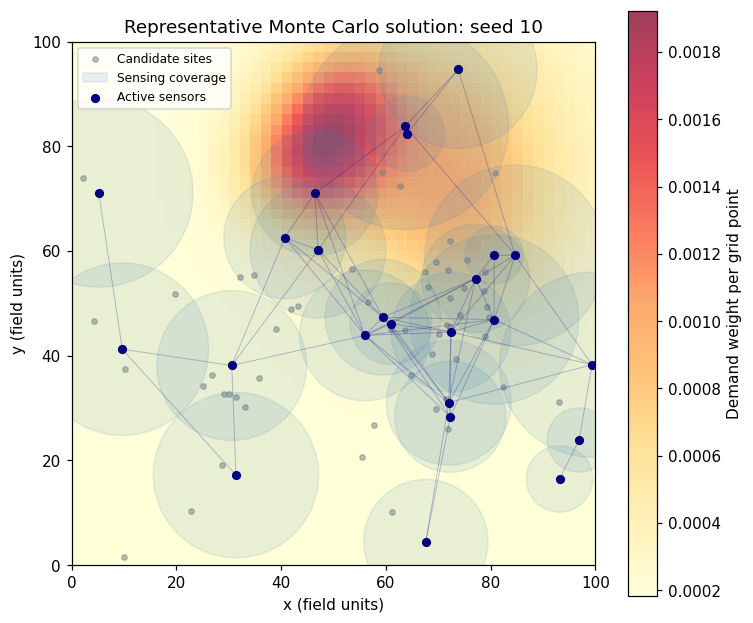

In [11]:
# Select a typical run for illustration, rather than the luckiest run.
mc_rep_index = int(np.argmin(np.abs(mc_scores - MC_BASELINE_MEDIAN)))
mc_rep_seed = SEEDS[mc_rep_index]
rep_active, rep_power, rep_result = mc_solutions[mc_rep_index]

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(instance.demand.reshape(spec.grid_size, spec.grid_size).T,
                  origin="lower", extent=[0, 100, 0, 100], cmap="YlOrRd", alpha=0.75)
ax.scatter(instance.candidates[:, 0], instance.candidates[:, 1],
           s=12, color="gray", alpha=0.5, label="Candidate sites")

indices = np.flatnonzero(rep_active)
radii = 4 * np.sqrt(rep_power[indices])
for k, site in enumerate(indices):
    ax.add_patch(plt.Circle(instance.candidates[site], radii[k],
                            color="steelblue", alpha=0.12,
                            label="Sensing coverage" if k == 0 else None))
for a in range(len(indices)):
    for b in range(a + 1, len(indices)):
        if instance.dist_between[indices[a], indices[b]] <= 2.5 * min(radii[a], radii[b]):
            xy = instance.candidates[[indices[a], indices[b]]]
            ax.plot(xy[:, 0], xy[:, 1], color="navy", lw=0.6, alpha=0.25)

ax.scatter(instance.candidates[indices, 0], instance.candidates[indices, 1],
           s=25, color="navy", label="Active sensors")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="x (field units)", ylabel="y (field units)",
       aspect="equal", title=f"Representative Monte Carlo solution: seed {mc_rep_seed}")
ax.legend(loc="upper left", fontsize=8)
fig.colorbar(image, ax=ax, label="Demand weight per grid point")
fig.tight_layout()
plt.show()

print(f"Representative seed: {mc_rep_seed} | objective: {rep_result.objective:.6f}")
print(f"Active sensors: {rep_result.n_active} | components: {rep_result.n_components}")
print(f"Coverage: {rep_result.coverage:.4f} | energy: {rep_result.energy:.4f} | interference: {rep_result.interference:.4f}")

### Baseline interpretation

The retained final deployment was connected in all 30 runs. Power assignments were sampled within each site's limits, and each run used exactly 5,000 objective evaluations. This establishes a baseline under the declared sampling procedure. It does not imply that every sampled deployment was feasible: disconnected proposals were evaluated with the supplied penalty and consumed the same evaluation budget.

Differences between the worst and best final scores across seeds describe between-run variability, not progressive improvement from one seed to the next. Improvement during search is shown by each run's best-so-far trace. The median trace summarizes those 30 traces at each evaluation count. Its enlarged view reveals additional gains that were visually compressed by the initial negative scores in the full view.

The objective balances demand coverage against energy, redundancy and infeasibility. Neither the number of active sensors nor the objective value alone establishes how much improvement remains, since the optimum is unknown. The median and interquartile range will be compared with other methods under the same budget before judging the baseline's quality and consistency.


In [12]:
print(
    f"Monte Carlo reached a median best objective of {MC_BASELINE_MEDIAN:.4f} "
    f"with Q1–Q3 [{MC_Q1:.4f}, {MC_Q3:.4f}] after {BUDGET:,} evaluations per run. "
    f"The best retained deployment was connected in {mc_feasible_bests}/{len(SEEDS)} runs."
)
print(
    "The low feasible fraction of individual random deployments does not imply "
    "that the best of 5,000 samples is usually disconnected. These are different measurements."
)
print(
    "Keeping the best makes the best-so-far trace nondecreasing, although the "
    "sampling distribution never learns from successful deployments. "
    "Further methods will be compared against this distribution-specific baseline."
)

Monte Carlo reached a median best objective of 0.5516 with Q1–Q3 [0.5407, 0.5612] after 5,000 evaluations per run. The best retained deployment was connected in 30/30 runs.
The low feasible fraction of individual random deployments does not imply that the best of 5,000 samples is usually disconnected. These are different measurements.
Keeping the best makes the best-so-far trace nondecreasing, although the sampling distribution never learns from successful deployments. Further methods will be compared against this distribution-specific baseline.


## Carry forward

The diagnostic measurements and Monte Carlo configuration and median are available. M0 still requires the nominal-power decision, coupling experiment, simulated annealing and paired comparison.

The table summarizes the current executed results; the named values remain defined in code below and in their experiment cells.

| Quantity / variable | Current value | Purpose |
|---|---:|---|
| `MC_BASELINE_MEDIAN` | 0.551577 | Reference objective for later method comparisons |
| `MC_PARAMS["active_fraction_range"]` | (0.1, 0.5) | Monte Carlo sampling configuration |
| `BUDGET` | 5,000 | Maximum objective evaluations per optimization run |
| `SEEDS` | 0–29 (30 seeds) | Paired execution identifiers for comparisons |
| `feasible_fraction` | 0.165 (16.5%) | Connected fraction under the characterization sampling procedure |
| `rho_1` | 0.9353 | Lag-1 objective autocorrelation for the declared walk |
| `WALK_POWER_STEP` | 3.0 | Standard deviation of power perturbations in the walk |
| `CHAR_SEED` | 10,000 | Reproduce random-deployment characterization |
| `WALK_SEED` | 10,001 | Reproduce the random walk |
| `N_DEPLOYMENTS` | 2,000 | Evaluations used for random-deployment characterization |
| `walk_problem.evaluations_used` | 1,001 | Initial evaluation plus 1,000 walk moves |
| `NOMINAL_POWER` | Pending | To be selected before the fixed-power subset searches |

Reported values are rounded for readability. Full-precision computed values remain in code. If the experiment settings or instance change, this summary must be refreshed from the new outputs. `NOMINAL_POWER` has not yet been assigned.


In [13]:
M0_DIAGNOSTICS = {
    "characterization_seed": CHAR_SEED,
    "walk_seed": WALK_SEED,
    "feasible_fraction": feasible_fraction,
    "rho_1": rho_1,
    "walk_power_step": WALK_POWER_STEP,
    "characterization_evaluations": characterization.evaluations_used,
    "walk_evaluations": walk_problem.evaluations_used,
}
print(M0_DIAGNOSTICS)
print(f"MC_BASELINE_MEDIAN = {MC_BASELINE_MEDIAN:.6f}")
print(f"MC_PARAMS = {MC_PARAMS}")
print("M0 still requires: nominal power, coupling experiment and annealing comparison.")

{'characterization_seed': 10000, 'walk_seed': 10001, 'feasible_fraction': 0.165, 'rho_1': 0.9352701174413995, 'walk_power_step': 3.0, 'characterization_evaluations': 2000, 'walk_evaluations': 1001}
MC_BASELINE_MEDIAN = 0.551577
MC_PARAMS = {'active_fraction_range': (0.1, 0.5)}
M0 still requires: nominal power, coupling experiment and annealing comparison.


# M1


# M2


# M3


# Analysis


# AI Ledger


This ledger is updated as the work progresses. Entries describe actual assistance;
the student's final acceptance and interpretation remain pending review.

| Tool / model | Prompt or task | Output | Verdict | Verification |
|---|---|---|---|---|
| ChatGPT / Codex; model identifier not independently verified in the notebook | Continue the uploaded sensor-placement notebook with formulation and initial M0 characterization. | Formulation, instance map, random-deployment sampling and an unconditional random walk. | Pending student review. | Independent single-sensor calculation; disconnected-pair penalty; power-cap equivalence; deterministic instance regeneration; batch and over-budget checks. Exact diagnostic counts are asserted in code. |

| ChatGPT / Codex; model identifier not independently verified in the notebook | Continue with the Monte Carlo baseline, retaining the revised preliminary interpretation. | Budget-limited random search, 30-seed study, summaries and representative deployment. | Pending student review. | Independent replay, retained-vector check, seeded repeatability and exact per-run budget assertions; executed results are reported in M0. |

At least one concrete AI error, its evidence and correction still need to be
documented. No error or student acceptance is fabricated here.

# Video